# Smoke3D

Smoke3D files (`&SMOKE3D`) are written for rendering smoke and fire in Smokeview.

> **These are display codes, not physical values.** Every value is a single byte between 0
> and 254. HRRPUV is scaled to `HRRPUV_MAX_SMV` (1200 kW/m³ by default) and cut off above
> it, soot is stored as obscuration (FDS < 6.11) or normalised per frame (FDS ≥ 6.11). Use
> slices, Plot3D or the CSV files for quantitative analysis; see
> [#115](https://github.com/FireDynamics/fdsreader/issues/115).

Run FDS on `fds_steckler/input_steckler.fds` first: the Steckler room with the default
Smoke3D output.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import fdsreader as fds

sim = fds.Simulation("./fds_steckler")
print([smoke.quantity for smoke in sim.smoke_3d])

[Quantity('SOOT DENSITY'), Quantity('HRRPUV'), Quantity('EFFECTIVE FLAME TEMPERATURE')]


The quantity names depend on the FDS version: FDS 6.11 writes the temperature as
`EFFECTIVE FLAME TEMPERATURE`. `SOOT DENSITY` is zero in this case, which sets no soot
yield, so the heat release rate per unit volume is shown.

In [2]:
hrrpuv = sim.smoke_3d.get_by_quantity("HRRPUV")
data, coords = hrrpuv.to_global(masked=True, fill=np.nan, return_coordinates=True)
print(data.shape, "values from", np.nanmin(data), "to", np.nanmax(data))

(101, 37, 29, 23) values from 0.0 to 254.0


The share of cells above zero shows when the fire burns:

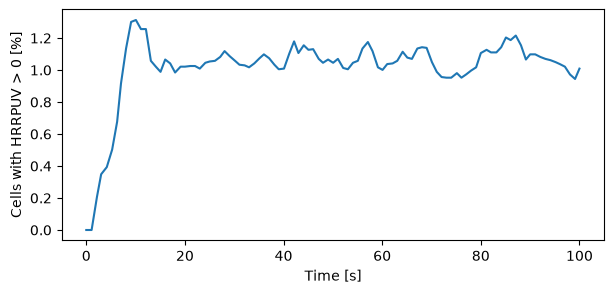

In [3]:
burning = (np.nan_to_num(data) > 0).mean(axis=(1, 2, 3))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(hrrpuv.times, 100 * burning)
ax.set(xlabel="Time [s]", ylabel="Cells with HRRPUV > 0 [%]");

## Render one frame

Zero is drawn transparent and the maximum opaque, similar to Smokeview. The grey band is
the masked wall with the door.

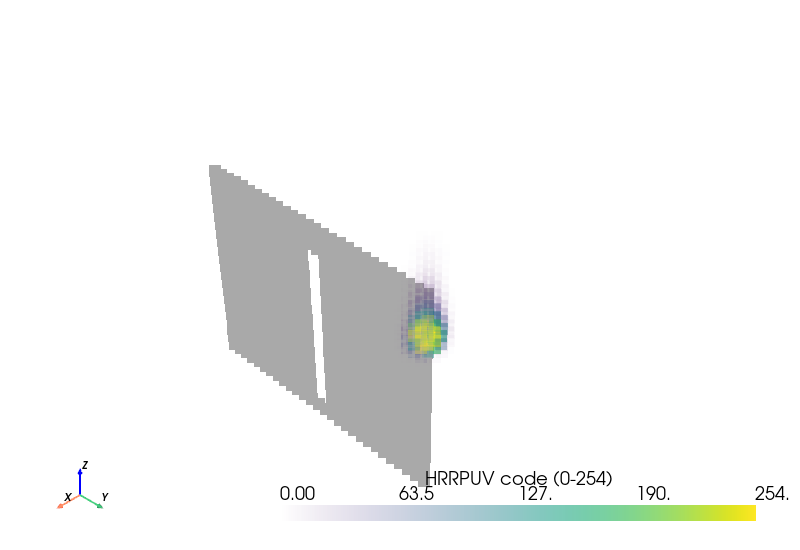

In [4]:
import pyvista as pv

# Render 3D views as static images, so they are stored in the notebook. Use "trame" or
# remove this line to rotate the views interactively.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 550]

t = int(np.argmin(np.abs(np.array(hrrpuv.times) - 60.0)))
x, y, z = np.meshgrid(coords["x"], coords["y"], coords["z"], indexing="ij")
frame = pv.PolyData(np.column_stack((x.ravel(), y.ravel(), z.ravel())))
frame["HRRPUV code"] = data[t].ravel()
frame.plot(opacity="linear", clim=(0, 254), point_size=12, scalar_bar_args={"title": "HRRPUV code (0-254)"})

More in the [API reference](https://fdsreader.readthedocs.io/en/latest/api/smoke3d.html).